# Vandermonde y cambio de base

M[i,j] = phi(x[i],j). Fila = nodo, columna = base. Resolver M @ A = y.

**Uso:** ejecuta los imports y el bloque del caso que necesites. Cada ejemplo empieza con sus propios datos. `def` se usa solo para expresiones matemáticas.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

## 1. Monomios

Cambia x e y. Los coeficientes están en orden ascendente.

M: [[1. 0. 0.]
 [1. 1. 1.]
 [1. 2. 4.]] A: [1. 0. 1.]


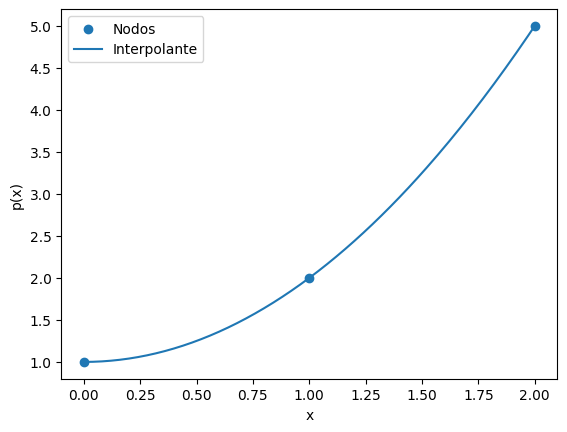

In [2]:
x=np.array([0.,1.,2.]); y=np.array([1.,2.,5.])
assert len(x)==len(y) and len(np.unique(x))==len(x)
m=len(x)
M=np.zeros((m,m))
for i in range(m):
    for j in range(m):
        M[i,j]=x[i]**j
A=np.linalg.solve(M,y)
print('M:',M,'A:',A)
z=np.linspace(x.min(),x.max(),201)
p=np.zeros(len(z))
for j in range(m):
    p += A[j]*z**j
assert np.allclose(M@A,y) and np.allclose(p,1+z**2)
plt.scatter(x,y,label='Nodos'); plt.plot(z,p,label='Interpolante'); plt.xlabel('x'); plt.ylabel('p(x)'); plt.legend(); plt.show()

## 2. Base cosenos — datos de clase

Solo cambia phi. Una matriz de base general puede ser singular aunque los nodos sean distintos.

A: [ 2.6       -2.4472136 -1.2472136 -1.5527864 -0.3527864] Condición: 4.614273206471733


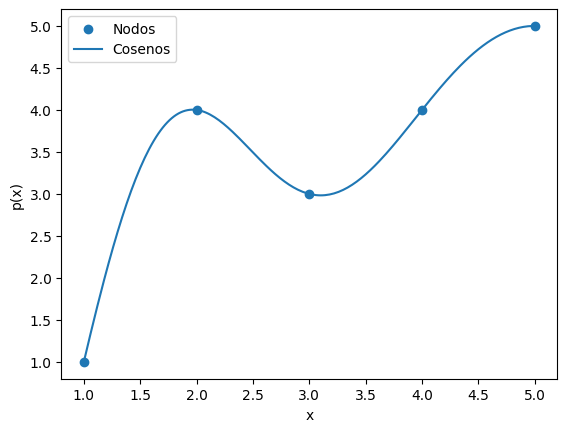

In [3]:
datos=np.genfromtxt('datos-01.txt')
x,y=datos[:,0],datos[:,1]
L=5.
def phi(x,j):
    return np.cos(j*np.pi*x/L)
m=len(x)
M=np.zeros((m,m))
for i in range(m):
    for j in range(m):
        M[i,j]=phi(x[i],j)
A=np.linalg.solve(M,y)
z=np.linspace(x.min(),x.max(),201)
p=np.zeros(len(z))
for j in range(m):
    p += A[j]*phi(z,j)
print('A:',A,'Condición:',np.linalg.cond(M))
assert np.allclose(M@A,y)
plt.scatter(x,y,label='Nodos'); plt.plot(z,p,label='Cosenos'); plt.xlabel('x'); plt.ylabel('p(x)'); plt.legend(); plt.show()

## 3. Base Legendre

Mismo algoritmo. SciPy solo evalúa P_j, no interpola; reemplaza phi si se exige otro método para calcular P_j. Habitualmente [-1,1].

In [4]:
from scipy.special import eval_legendre
def phi(x,j):
    return eval_legendre(j,x)
x=np.array([-1.,-.3,.5,1.]); y=1+x**2
m=len(x)
M=np.zeros((m,m))
for i in range(m):
    for j in range(m):
        M[i,j]=phi(x[i],j)
A=np.linalg.solve(M,y)
z=np.linspace(-1,1,201)
p=np.zeros(len(z))
for j in range(m):
    p += A[j]*phi(z,j)
print('Coeficientes Legendre:',A)
assert np.allclose(M@A,y) and np.allclose(p,1+z**2)

Coeficientes Legendre: [ 1.33333333e+00 -6.90859661e-17  6.66666667e-01  6.90859661e-17]


## 4. Error y número de nodos

Compara en una malla independiente de los nodos. El máximo en la malla es una estimación. Si solo tienes datos, no conoces el error real entre nodos.

[[4.00000000e+00 9.98466893e-03 8.01156105e+00]
 [8.00000000e+00 7.98894499e-07 5.35353118e+02]
 [1.20000000e+01 1.32809319e-11 4.07548818e+04]]


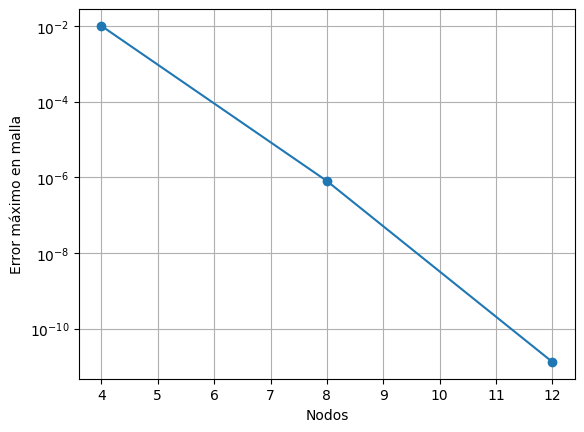

In [5]:
def f(x):
    return np.exp(x)
def phi(x,j):
    return x**j
cantidades=np.array([4,8,12])
errores=np.zeros(len(cantidades)); condiciones=np.zeros(len(cantidades))
z=np.linspace(-1,1,501)
for k in range(len(cantidades)):
    m=cantidades[k]
    x=np.linspace(-1,1,m); y=f(x)
    M=np.zeros((m,m))
    for i in range(m):
        for j in range(m):
            M[i,j]=phi(x[i],j)
    A=np.linalg.solve(M,y)
    p=np.zeros(len(z))
    for j in range(m):
        p += A[j]*phi(z,j)
    errores[k]=np.max(np.abs(f(z)-p))
    condiciones[k]=np.linalg.cond(M)
print(np.column_stack((cantidades,errores,condiciones)))
plt.semilogy(cantidades,errores,'o-'); plt.xlabel('Nodos'); plt.ylabel('Error máximo en malla'); plt.grid(); plt.show()

Material de estudio adaptado del notebook de clases y de la versión FC2_C2. Ejemplos de práctica; no son soluciones de las tareas. Comprueba las reglas de uso de material asistido por IA.